### **1. Setting Up**

In [1]:
# Change working directory
import os
tissue_path = os.path.join(os.getcwd(), "TISSUE")
os.chdir(tissue_path)

# import packages
import tissue.main, tissue.downstream
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
import scipy.stats as st

### **2. Loading Datasets and Exploration**

In [10]:
# import os
# print(os.getcwd())
os.chdir('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation')

RNAseq_adata = sc.read('gene_data/ageing_rna_20250114.h5ad')

adata = sc.read('gene_data/ag02reg00_rawcounts.h5ad')

/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


### **3. Data Pre-Processing and Training Gene Selection**

In [11]:
# Cortex Filtering - remove other regions
# Coordinates
x = adata.obs['center_x'].values
y = adata.obs['center_y'].values

# Ellipse centre
x0 = np.median(x) - 240
y0 = np.median(y) - 280

# Ellipse semi-axes — tune these for your brain slice - can add outer if I want to extract a subcortical layer (two more a and b params)
a = 1850  
b = 1600

# Define rectangular bounds - to remove the bottom bit
remove_mask = (x > 2400) & (y < 7950)
keep_mask = ~remove_mask

# Ellipse equations
# outer_ellipse = ((x - x0) / a_outer) ** 2 + ((y - y0) / b_outer) ** 2 < 1
inner_ellipse = ((x - x0) / a) ** 2 + ((y - y0) / b) ** 2 > 1 

# Cortex mask: in outer ellipse but not inner
cortex_mask = inner_ellipse & keep_mask
adata = adata[cortex_mask, :].copy()

WHY IS THE SPATIAL DATA NOT NORMALISED IN THE TUTORIAL WTH

In [12]:
# make genes lowercase
adata.var_names = [x.lower() for x in adata.var_names]
RNAseq_adata.var_names = [x.lower() for x in RNAseq_adata.var_names]

# # preprocess RNAseq data
# tissue.main.preprocess_data(RNAseq_adata, standardize=False, normalize=True)
# tissue.main.preprocess_data(adata, standardize=False, normalize=True)

# subset spatial data into shared genes (the tutorial does not include the extra line that I added)
gene_names = np.intersect1d(adata.var_names, RNAseq_adata.var_names)
adata = adata[:, gene_names].copy()
RNAseq_adata = RNAseq_adata[:, gene_names].copy()

In [13]:
# hold out target gene
target_gene = "ccnd2"
target_expn = adata[:, target_gene].X.copy()
adata = adata[:, [gene for gene in gene_names if gene != target_gene]].copy()

In [14]:
# SpaGE spatial gene expression prediction

tissue.main.predict_gene_expression (adata, RNAseq_adata, [target_gene],
                                     method="spage", n_folds=10, n_pv=10)

/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/TISSUE/tissue/main.py:377: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  predicted_expression_target[conf_genes] = predicted_expression_conf[conf_genes].copy()
/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/TISSUE/tissue/main.py:377: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  predicted_expression_target[conf_genes] = predict

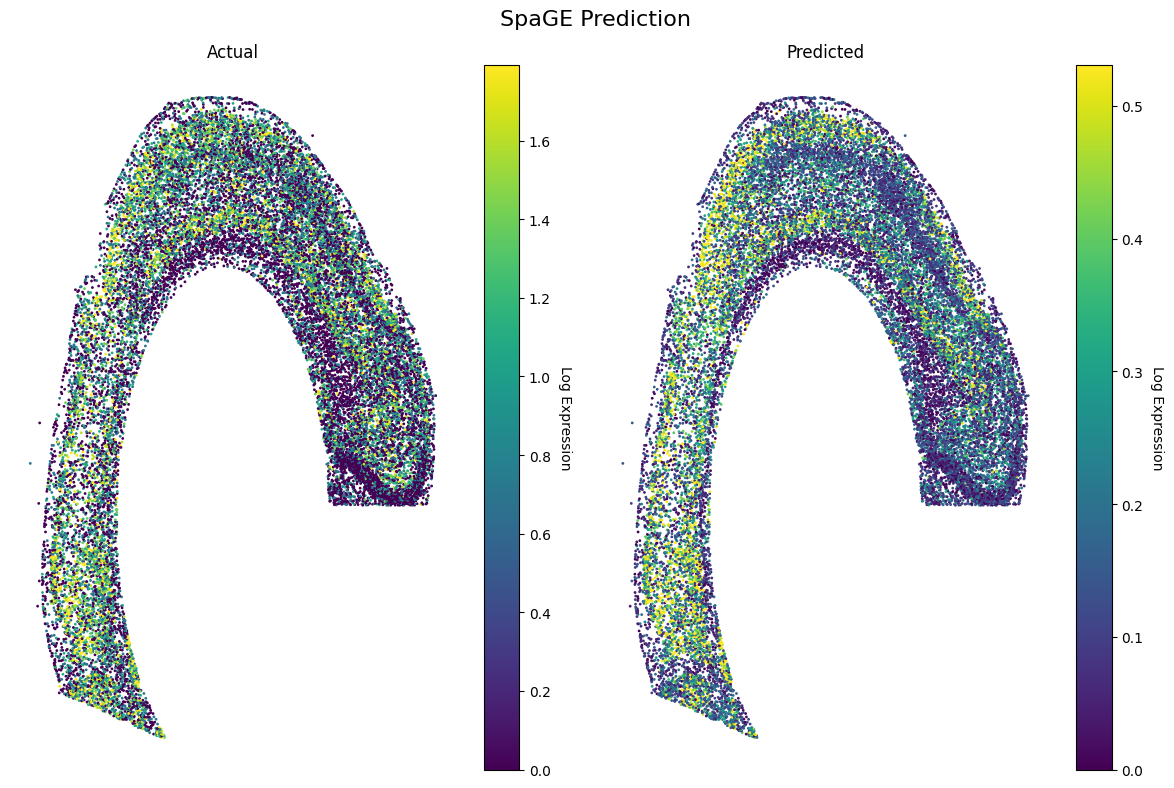

In [15]:
# Visualizing predicted and actual expression side by side

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

ax1.axis('off')
cmap = target_expn
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax1.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
# im = ax1.scatter(adata.obsm['spatial'][:,0],adata.obsm['spatial'][:,1],s=1,c=cmap,rasterized=True)
ax1.set_title('Actual', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

ax2.axis('off')
cmap = adata.obsm['spage_predicted_expression'][target_gene].values
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax2.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
ax2.set_title('Predicted', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

plt.suptitle("SpaGE Prediction", fontsize=16)
plt.tight_layout()
plt.show()

In [16]:
print(st.pearsonr(target_expn.flatten(), adata.obsm['spage_predicted_expression'][target_gene].values)[0])

0.5158756835975828


51.82077286733217 7123.841988413034
4869.512563907543 10509.034411992989


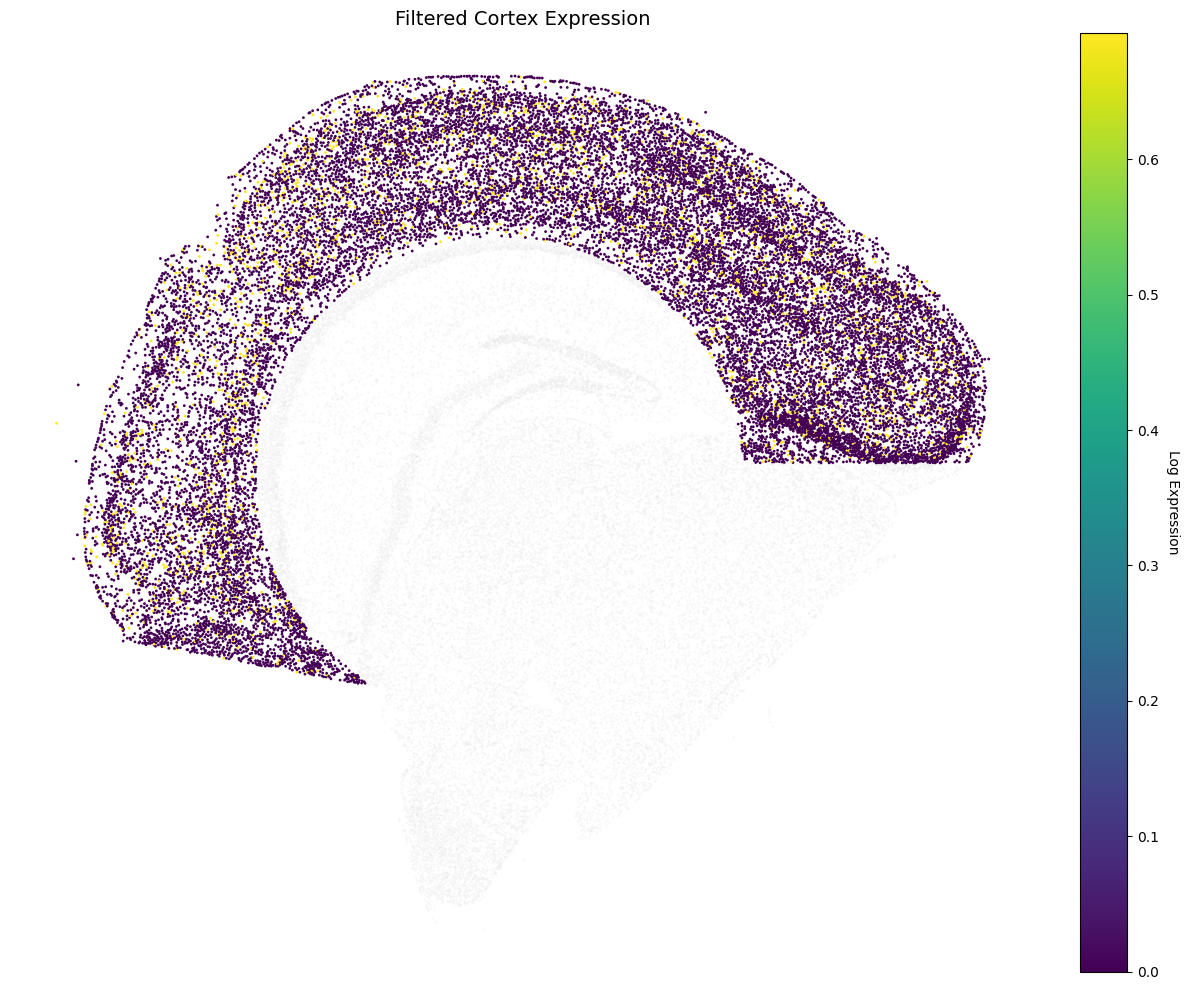

In [90]:
# Prepare the colour map
cmap = target_expn.copy()
cmap[cmap < 0] = 0
cmap = np.log1p(cmap)
clip_val = np.percentile(cmap, 95)
cmap[cmap > clip_val] = clip_val

# Coordinates
x = adata.obs['center_x'].values
y = adata.obs['center_y'].values

print(min(x), max(x))
print(min(y), max(y))

# Ellipse centre (use median or mean)
x0 = np.median(x) - 240
y0 = np.median(y) - 280

# Ellipse semi-axes — tune these for your brain slice - can add outer if I want to extract a subcortical layer
# a_outer = 20000  # width radius
# b_outer = 5000  # height radius
a = 1850  # inner shell cut-out
b = 1600

# Define rectangular bounds — adjust based on your data range
remove_mask = (x > 2400) & (y < 7950)
keep_mask = ~remove_mask

# Ellipse equations
# outer_ellipse = ((x - x0) / a_outer) ** 2 + ((y - y0) / b_outer) ** 2 < 1
inner_ellipse = ((x - x0) / a) ** 2 + ((y - y0) / b) ** 2 > 1 

# Cortex mask: in outer ellipse but not inner
cortex_mask = inner_ellipse & keep_mask

# Apply mask
x_cortex = x[cortex_mask]
y_cortex = y[cortex_mask]
cmap_cortex = cmap[cortex_mask]

# Plot
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
ax.axis('off')

# Plot all cells in grey (optional for context)
ax.scatter(x, y, s=1, c='lightgrey', alpha=0.1, rasterized=True)

# Plot cortex cells in colour
im = ax.scatter(x_cortex, y_cortex, s=1, c=cmap_cortex, rasterized=True)

# Title and colourbar
ax.set_title('Filtered Cortex Expression', fontsize=14)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

plt.tight_layout()
plt.show()

In [65]:
def annotate_gene_sparsity(adata):
    """
    Annotates gene sparsity in given Anndatas. 
    Update given Anndata by creating `var` "sparsity" field with gene_sparsity (1 - % non-zero observations).

    Args:
        adata (Anndata): single cell or spatial data.

    Returns:
        None
    """
    mask = adata.X != 0
    gene_sparsity = np.sum(mask, axis=0) / adata.n_obs
    gene_sparsity = np.asarray(gene_sparsity)
    gene_sparsity = 1 - np.reshape(gene_sparsity, (-1,))
    adata.var["sparsity"] = gene_sparsity

annotate_gene_sparsity(adata_sc)
annotate_gene_sparsity(adata_st)

NameError: name 'adata_sc' is not defined

### **4. Find alignment and Validate SpaGE using LOO Cross-Validation**

In [7]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.array(y_true) - np.array(y_pred)) ** 2))

In [ ]:
Gene_set = shared_genes

# Metric storage, score and sparsity data - train_score here is cosine similarity
metrics_df = pd.DataFrame(columns=['Pearson', 'Spearman', 'train_score', 'RMSE', 'sparsity_sc', 'sparsity_sp', 'sparsity_diff'], index=Gene_set)

plt.style.use('dark_background')

for i in Gene_set:
  Imp_Genes = SpaGE(adata_st_df.drop(i,axis=1),adata_sc_df, n_pv=30, genes_to_predict = [i])
  metrics_df.loc[i, 'Pearson'] = st.pearsonr(adata_st_df[i], Imp_Genes[i])[0]
  metrics_df.loc[i, 'Spearman'] = st.spearmanr(adata_st_df[i], Imp_Genes[i])[0]
  metrics_df.loc[i, 'RMSE'] = rmse(adata_st_df[i], Imp_Genes[i])

  v1 = adata_st_df[i].values
  v2 = Imp_Genes[i].values
  if np.linalg.norm(v1) == 0 or np.linalg.norm(v2) == 0:
      metrics_df.loc[i, 'Cosine'] = np.nan
  else:
      metrics_df.loc[i, 'Cosine'] = (v1 @ v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

  fig, (ax1, ax2) = plt.subplots(1, 2)
  ax1.axis('off')
  cmap = adata_st_df[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)        # Sets a maximum values for the 99th percentile
  ax1.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax1.set_title('Measured ' + i, fontsize = 12)
  ax1.set_ylabel(i)

  ax2.axis('off')
  cmap = Imp_Genes[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)
  ax2.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax2.set_title('Predicted ' + i, fontsize = 12)

In [8]:
metrics_df = pd.read_csv('metrics_df.csv')
metrics_df.set_index('Unnamed: 0', inplace=True)

In [10]:
print(metrics_df)

             Pearson  Spearman    Cosine      RMSE
Unnamed: 0                                        
Igf2        0.371729  0.157022  0.427934  1.650926
Ngfr        0.026501  0.027379  0.054764  0.594322
Ccnd2       0.410857  0.378840  0.683812  2.638821
Lhx2        0.206493  0.199312  0.333604  0.995367
Glra3       0.328441  0.289098  0.436994  1.220297
...              ...       ...       ...       ...
Qpct             NaN       NaN       NaN       NaN
Adra2a           NaN       NaN       NaN       NaN
Gal              NaN       NaN       NaN       NaN
Gpr52            NaN       NaN       NaN       NaN
Aqp4             NaN       NaN       NaN       NaN

[464 rows x 4 columns]


### **5. Plotting the Results**

In [11]:
# Extract sparsity as DataFrames with explicit column names
df_sparsity_sp = pd.DataFrame(
    adata_st[:, shared_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sp"})

df_sparsity_sc = pd.DataFrame(
    adata_sc[:, shared_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sc"})

# Merge the two sparsity DataFrames
df_sparsity = df_sparsity_sp.merge(
    df_sparsity_sc, left_index=True, right_index=True
)

# Calculate the difference
df_sparsity["sparsity_diff"] = np.abs(df_sparsity["sparsity_sp"] - df_sparsity["sparsity_sc"])

# Merge with the existing metrics
new_metrics_df = metrics_df.merge(
    df_sparsity, left_index=True, right_index=True
)

In [13]:
new_metrics_df = new_metrics_df[new_metrics_df['Pearson'].notna()]

**1. Training scores vs Sparsity**

In [15]:
def plot_training_scores(metrics_df, bins=10, alpha=0.7):
    """
    Plots the 4-panel training diagnosis plot using the metrics_df.

    Args:
        metrics_df (pd.DataFrame): Must contain columns: 'train_score', 'sparsity_sc', 'sparsity_sp', 'sparsity_diff'.
        bins (int or string): Number of histogram bins. Default is 10.
        alpha (float): Opacity of scatter plot points. Default is 0.7.

    Returns:
        None
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    fig, axs = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
    axs_f = axs.flatten()

    axs_f[0].set_ylim([0.0, 1.0])
    for i in range(1, len(axs_f)):
        axs_f[i].set_xlim([0.0, 1.0])
        axs_f[i].set_ylim([0.0, 1.0])

    sns.histplot(data=metrics_df, y="Cosine", bins=bins, ax=axs_f[0], color="coral")
    axs_f[0].set_title("Train score distribution")

    axs_f[1].set_title("Score vs sparsity (single-cell)")
    sns.scatterplot(
        data=metrics_df,
        y="Cosine",
        x="sparsity_sc",
        ax=axs_f[1],
        alpha=alpha,
        color="coral",
    )

    axs_f[2].set_title("Score vs sparsity (spatial)")
    sns.scatterplot(
        data=metrics_df,
        y="Cosine",
        x="sparsity_sp",
        ax=axs_f[2],
        alpha=alpha,
        color="coral",
    )

    axs_f[3].set_title("Score vs sparsity (sp - sc)")
    sns.scatterplot(
        data=metrics_df,
        y="Cosine",
        x="sparsity_diff",
        ax=axs_f[3],
        alpha=alpha,
        color="coral",
    )

    plt.tight_layout()


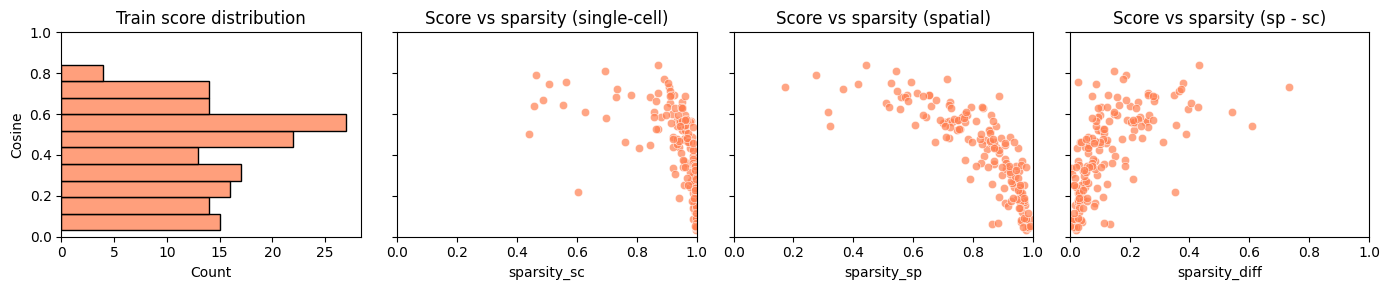

In [16]:
plot_training_scores(new_metrics_df)

**2. Plot AUC**
-  adjusted code without chatGPT

In [ ]:
# Assuming new_metrics_df is your DataFrame

shared_genes = new_metrics_df.index

# Calculate metrics
test_gene_scores = new_metrics_df.loc[shared_genes, "Cosine"]
test_gene_sparsity_sp = new_metrics_df.loc[shared_genes, "sparsity_sp"]
test_score_avg = test_gene_scores.mean()


# sp sparsity weighted score - metric across all genes
test_score_sps_sp_g2 = np.sum(
    (test_gene_scores * (1 - test_gene_sparsity_sp))
    / (1 - test_gene_sparsity_sp).sum()
)

# Fit polynomial (degree 2)
xs = list(test_gene_sparsity_sp)
ys = list(test_gene_scores)
pol_deg = 2
pol_cs = np.polyfit(xs, ys, pol_deg)  # polynomial coefficients
pol = np.poly1d(pol_cs)  # build polynomial as function


# Generate polynomial y-values
pol_xs = np.linspace(0, 1, 10)  # x linearly spaced
pol_ys = [pol(x) for x in pol_xs]  # compute polynomial y-values

# Debugging: print polynomial x and y values
print("Normal X values:", xs)
print("Normal Y values:", ys)
print("Polynomial X values:", pol_xs)
print("Polynomial Y values:", pol_ys)

# # Constrain y values to 1 or less
# if pol_ys[0] > 1:
#     pol_ys[0] = 1

# # Check for real roots
# roots = pol.r
# root = None
# for i in range(len(roots)):
#     if np.isreal(roots[i]) and roots[i] <= 1 and roots[i] >= 0:
#         root = roots[i]
#         break

# # Debugging: print roots
# print("Polynomial Roots:", roots)

# # Add the root to the polynomial if found
# if root is not None:
#     pol_xs = np.append(pol_xs, root)
#     pol_ys = np.append(pol_ys, 0)

# # Add the endpoint to the polynomial
# pol_xs = np.append(pol_xs, 1)
# pol_ys = np.append(pol_ys, pol(1))

# # Debugging: print updated polynomial x and y values
# print("Updated Polynomial X values:", pol_xs)
# print("Updated Polynomial Y values:", pol_ys)

# # Filter out points that are beyond the [0, 1] x,y range
# del_idx = []
# for i in range(len(pol_xs)):
#     if pol_xs[i] < 0 or pol_ys[i] < 0 or pol_xs[i] > 1 or pol_ys[i] > 1:
#         del_idx.append(i)

# # Debugging: print indices to be deleted
# print("Indices to be deleted:", del_idx)

# # Apply the deletion
# pol_xs = [x for i, x in enumerate(pol_xs) if i not in del_idx]
# pol_ys = [y for i, y in enumerate(pol_ys) if i not in del_idx]

# # Debugging: print final polynomial x and y values
# print("Final Polynomial X values:", pol_xs)
# print("Final Polynomial Y values:", pol_ys)

# # Compute area under the curve (AUC) of the polynomial
# auc_test_score = np.real(auc(pol_xs, pol_ys))

# # Debugging: print AUC score
# print("AUC Score:", auc_test_score)

# # Collect metrics in a dictionary
# metric_dict = {
#     "avg_test_score": test_score_avg,
#     "sp_sparsity_score": test_score_sps_sp_g2,
#     "auc_score": auc_test_score,
# }

# # Print the metric dictionary
# print("Metric Dictionary:", metric_dict)

# # Prepare AUC coordinates
# auc_coordinates = ((pol_xs, pol_ys), (xs, ys))


Normal X values: [0.4279344219632702, 0.0547639290730854, 0.6838116353797008, 0.3336042398936402, 0.4369942460685144, 0.5159098631133984, 0.6263363239388475, 0.4851434485102013, 0.595095919505589, 0.5204222914011621, 0.5704228387412292, 0.1530658091096827, 0.3562111058627237, 0.7897807139768012, 0.5283954169194679, 0.3223904065112101, 0.6910958337857536, 0.5221799944053103, 0.7489217572088755, 0.5983829816495374, 0.4824176173834901, 0.3451958864386981, 0.3936737018925256, 0.0771601657650504, 0.1710524689307975, 0.4586569825892949, 0.4618791466870354, 0.3714033533356241, 0.2680983229374348, 0.0708816494185729, 0.3605304980257729, 0.4797203899412617, 0.5628664070841372, 0.5682993426975353, 0.0825640353114762, 0.4344931777816525, 0.2136700090477619, 0.2544971675126565, 0.2099220280172467, 0.1811453219999494, 0.4612389913323004, 0.5843309158098693, 0.3032382680201368, 0.4401743382487101, 0.4094580612979833, 0.1655506586294922, 0.3298178378313166, 0.4261243561275326, 0.0305161753255844, 0.5

In [36]:
def eval_metric(df_metrics):
    """
    Compute metrics on given test_genes set for evaluation
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:      
        dict with values of each evaluation metric ("avg_test_score", "avg_train_score", "auc_score"), 
        tuple of auc fitted coordinates and raw coordinates(test_score vs. sparsity_sp coordinates)
    """

    shared_genes = new_metrics_df.index

    # calculate:
    test_gene_scores = new_metrics_df.loc[shared_genes]["Cosine"]
    test_gene_sparsity_sp = new_metrics_df.loc[shared_genes]["sparsity_sp"]
    test_score_avg = test_gene_scores.mean()

    # sp sparsity weighted score - metric across all genes
    test_score_sps_sp_g2 = np.sum(
        (test_gene_scores * (1 - test_gene_sparsity_sp))
        / (1 - test_gene_sparsity_sp).sum()
    )

    # tm metric
    # Fit polynomial'
    xs = list(test_gene_sparsity_sp)   # x-axis
    ys = list(test_gene_scores)        # y-axis
    pol_deg = 2
    pol_cs = np.polyfit(xs, ys, pol_deg)  # Fit y = f(x)
    pol = np.poly1d(pol_cs)
    # Generate fitted values
    pol_xs = np.linspace(0, 1, 10)
    pol_ys = [pol(x) for x in pol_xs]
    # Clip y values to maximum of 1
    pol_ys = [min(y, 1) for y in pol_ys]

    # Constrains y values to 1 or less
    if pol_ys[0] > 1:
        pol_ys[0] = 1

    # Try to add a root if the polynomial crosses y = 0 within [0,1]
    roots = pol.r
    root = None
    for r in roots:
        if np.isreal(r) and 0 <= r <= 1:
            root = np.real(r)
            break
    if root is not None:
        pol_xs = np.append(pol_xs, root)
        pol_ys = np.append(pol_ys, 0)


    # Add right endpoint (x=1) explicitly
    pol_xs = np.append(pol_xs, 1)
    pol_ys = np.append(pol_ys, pol(1))

    # Filter out any x or y values outside [0, 1]
    filtered = [(x, y) for x, y in zip(pol_xs, pol_ys) if 0 <= x <= 1 and 0 <= y <= 1]
    pol_xs, pol_ys = zip(*sorted(filtered)) if filtered else ([], [])

    # Compute are under the curve of polynomial
    auc_test_score = np.real(auc(pol_xs, pol_ys))

    metric_dict = {
        "avg_test_score": test_score_avg,
        "sp_sparsity_score": test_score_sps_sp_g2,
        "auc_score": auc_test_score,
    }

    auc_coordinates = ((pol_xs, pol_ys), (xs, ys))

    return metric_dict, auc_coordinates


In [39]:
def plot_auc(df_all_genes, test_genes=None):
    """
        Plots auc curve which is used to evaluate model performance.
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:
        None
    """
    metric_dict, ((pol_xs, pol_ys), (xs, ys)) = eval_metric(df_all_genes)
    
    fig = plt.figure()
    plt.figure(figsize=(6, 5))

    plt.plot(pol_xs, pol_ys, c='r')
    sns.scatterplot(x=xs, y=ys, alpha=0.5, edgecolors='face')
        
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.gca().set_aspect(.5)
    plt.xlabel('score')
    plt.ylabel('spatial sparsity')
    plt.tick_params(axis='both', labelsize=8)
    plt.title('Prediction on test transcriptome')
    
    textstr = 'auc_score={}'.format(np.round(metric_dict['auc_score'], 3))
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.3)
    # place a text box in upper left in axes coords
    plt.text(0.03, 0.1, textstr, fontsize=11, verticalalignment='top', bbox=props);




<Figure size 640x480 with 0 Axes>

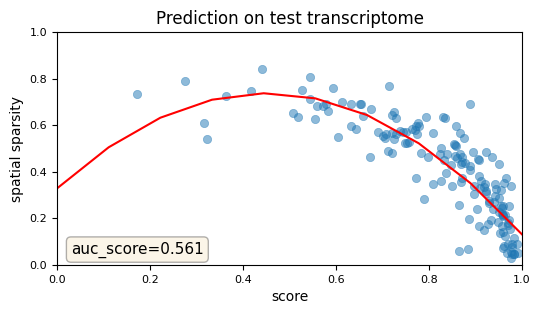

In [40]:
plot_auc(new_metrics_df)